# Regression
- Linear Regression with one variable (univariate)
- Cost Function
- Gradient Descent
- Linear Regression with multiple variables (Multivariate)
- Polynomial Regression
- Feature Engineering
- Feature Scaling

### Input and Output

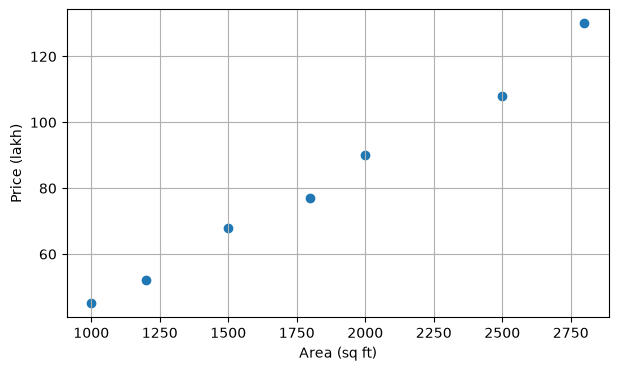

In [133]:
import numpy as np
import matplotlib.pyplot as plt

area = np.array([1000,1200,1500,1800,2000,2500,2800]) #in sqft
price = np.array([45,52,68,77,90,108,130]) #in lakhs

plt.figure(figsize=(7,4))
plt.scatter(area, price, label="Actual Sale Prices")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (lakh)")
plt.grid(True)
plt.show()


#### Hit and trial to find the best line -> f(x) = X*w+b

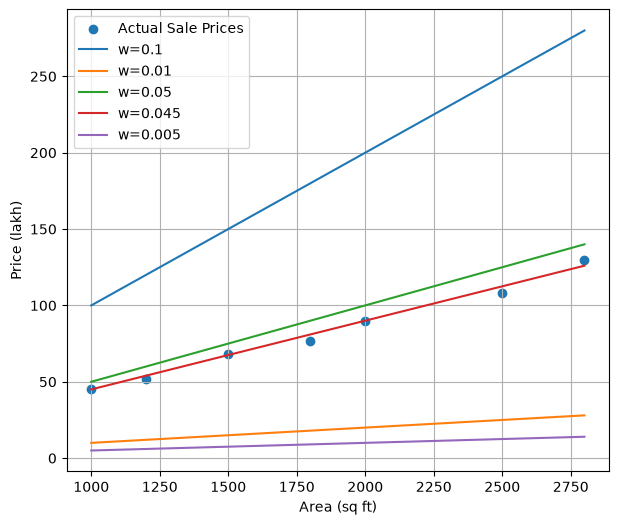

In [139]:
def predict(X, w, b):
    return X*w+b

plt.figure(figsize=(7,6))
plt.scatter(area, price, label="Actual Sale Prices")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (lakh)")
plt.grid(True)
area_line= np.linspace(area.min(), area.max(),100)

weights = [0.1, 0.01,0.05, 0.045, 0.005 ]

for w in weights:
    price_line = predict(area_line, w, 0)
    plt.plot(area_line, price_line, label=f"w={w}")

plt.legend()
plt.show()

### Calculate Error for each line

w cost
0.005 2926.8928571428573
0.01 2236.285714285714
0.045 4.035714285714286
0.05 56.857142857142854
0.1 5696.142857142857


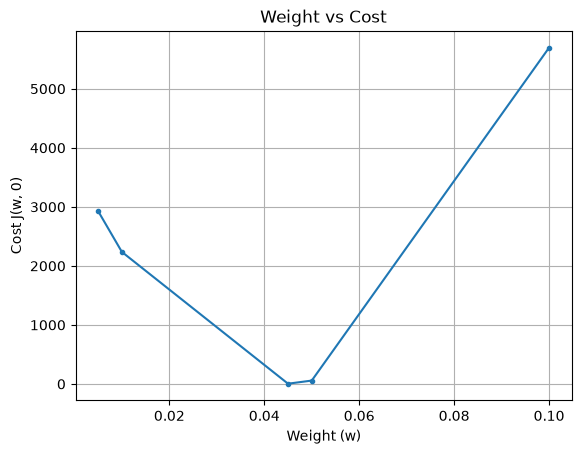

In [127]:
def calculate_cost(X,w,b,y):
    m= len(y)
    errors= predict(X,w,b) - y
    return (errors **2).sum()/ (2*m)

costs=[]
weights.sort()
print("w", "cost")
for w in weights:
    cost=calculate_cost(area,w,0,price)
    print(w, cost)
    costs.append(cost)

plt.plot(weights, costs, marker=".")
plt.xlabel("Weight (w)")
plt.ylabel("Cost J(w, 0)")
plt.title("Weight vs Cost")
plt.grid(True)
plt.show()


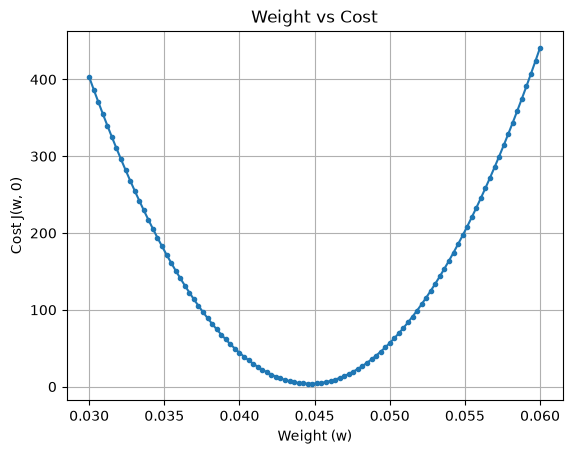

Weight with the least cost:  0.04454545454545454
Lowest cost: 3.8417945690672903


In [128]:

costs={}

weights = np.linspace(0.03, 0.06, 100)

for w in weights:
    cost=calculate_cost(area,w,0,price)
    costs[w]=cost


plt.plot(list(costs.keys()),list(costs.values()), marker=".")
plt.xlabel("Weight (w)")
plt.ylabel("Cost J(w, 0)")
plt.title("Weight vs Cost")
plt.grid(True)
plt.show()

best_w = min(costs, key=costs.get)
print("Weight with the least cost: ", best_w)
print("Lowest cost:", costs[best_w])


## Gradient Descent


In [129]:
def compute_gradient(X,w, b, y):
    avg_error=[]

    for i in range(0, len(y)):
        error = predict(X[i], w, b) - y[i] 
        avg_error.append(error*X[i])

    return sum(avg_error)/len(y)

print(compute_gradient(area, 0.03, b=0, y=price))
print(compute_gradient(area, 0.04454, b=0, y=price))
print(compute_gradient(area, 0.06, b=0, y=price))

-54485.71428571428
-438.45714285713046
57028.57142857143


**Gradient:** 

Tells us which direction the cost is increasing and how steeply it changes locally.


**Learning rate:** 

Controls how big a step we take. A large learning rate can overshoot the minimum; a small one can make progress very slowly.


**Cost:**

Tells us how poorly the current model fits the training data. We want to reduce it.

In [130]:
w = 0.03
alpha = 0.0000001

gradient = compute_gradient(area, w, 0, price)
w_new = w - alpha * gradient

print("Old weight:", w)
print("Gradient:", gradient)
print("New weight:", w_new)
print("Old cost:", calculate_cost(area, w, 0, price))
print("New cost:", calculate_cost(area, w_new, 0, price))

Old weight: 0.03
Gradient: -54485.71428571428
New weight: 0.035448571428571427
Old cost: 403.14285714285717
New cost: 161.44883205830908


#### How to retrieve the minimum cost using gradient descent without hit and trial

C:\Users\Nikita\AppData\Local\Temp\ipykernel_8084\2336843217.py:4: RuntimeWarning: overflow encountered in square
  return (errors **2).sum()/ (2*m)
c:\Users\Nikita\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\core\_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
C:\Users\Nikita\AppData\Local\Temp\ipykernel_8084\1737425425.py:6: RuntimeWarning: overflow encountered in scalar multiply
  avg_error.append(error*X[i])
C:\Users\Nikita\AppData\Local\Temp\ipykernel_8084\1737425425.py:8: RuntimeWarning: overflow encountered in scalar add
  return sum(avg_error)/len(y)
C:\Users\Nikita\AppData\Local\Temp\ipykernel_8084\3592335702.py:6: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - alpha* gradient


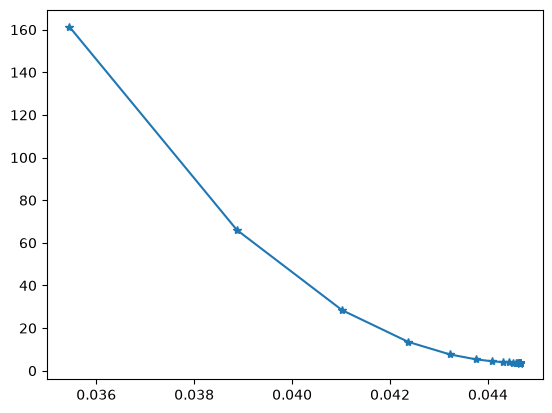

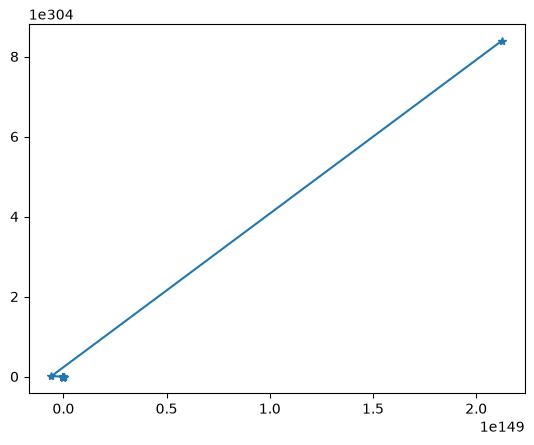

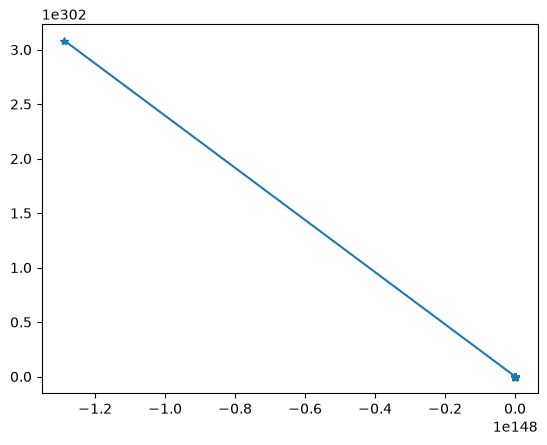

Grad 1 Minimum cost was 3.818271659163272 at w 0.044657955418862715
Grad 2 Minimum cost was 522469.0226239067 at w 0.5748571428571428
Grad 3 Minimum cost was 5514559813.871719 at w 54.51571428571428


In [132]:
def compute_gradient_descent(X,w,b,y, iterations, alpha):
    m = len(y)
    costs={}
    for _ in range(iterations):
        gradient = compute_gradient(X,w,b,y)
        w = w - alpha* gradient
        costs[w]=calculate_cost(X,w,b,y)


    return costs
    

grad1=compute_gradient_descent(area, w=0.03, b=0,y=price, iterations=100, alpha=0.0000001)
grad2=compute_gradient_descent(area, w=0.03, b=0,y=price, iterations=100, alpha=0.00001)
grad3=compute_gradient_descent(area, w=0.03, b=0,y=price, iterations=100, alpha=0.001)

plt.plot(list(grad1.keys()), list(grad1.values()), marker="*")
plt.show()
plt.plot(list(grad2.keys()), list(grad2.values()), marker="*")
plt.show()
plt.plot(list(grad3.keys()), list(grad3.values()), marker="*")
plt.show()


best_w1 = min(grad1, key = grad1.get)
print(f"Grad 1 Minimum cost was {grad1[best_w1]} at w {best_w1}")


best_w2 = min(grad2, key = grad2.get)
print(f"Grad 2 Minimum cost was {grad2[best_w2]} at w {best_w2}")


best_w3 = min(grad3, key = grad3.get)
print(f"Grad 3 Minimum cost was {grad3[best_w3]} at w {best_w3}")
